In [1]:
import numpy as np
import pandas as pd
from pathlib import Path

SEED = 42  
TRAIN_PATH = "../../../src/data/classificationdata/H2_classification_train_with_agent.csv"
TEST_PATH = "../../../src/data/classificationdata/H2_classification_test_with_agent.csv"
TARGET = "IsCanceled"

In [2]:
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)

train.columns = train.columns.str.strip()
test.columns = test.columns.str.strip()

print("train:", train.shape)
print("test :", test.shape)

train: (43332, 55)
test : (12343, 55)


In [3]:
# #Cell 3: basic checks
# The first line checks both files have the same columns in the same order. If not, the model will break.
# isna().sum().sum() counts empty cells. We want 0.
# duplicated().sum() counts repeated rows.
# value_counts(normalize=True) shows the share of 0s and 1s. About 42% of the original data is canceled. If the rates differ a lot between files, something is wrong.
print("Same columns in both files:", list(train.columns) == list(test.columns))
print("Missing values  train:", train.isna().sum().sum(), " test:", test.isna().sum().sum())
print("Duplicate rows  train:", train.duplicated().sum(), " test:", test.duplicated().sum())

print("\nCancel rate (1 = canceled)")
print("train:", train[TARGET].value_counts(normalize=True).round(3).to_dict())
print("test :", test[TARGET].value_counts(normalize=True).round(3).to_dict())

Same columns in both files: True
Missing values  train: 0  test: 0
Duplicate rows  train: 653  test: 367

Cancel rate (1 = canceled)
train: {0: 0.698, 1: 0.302}
test : {0: 0.675, 1: 0.325}


In [4]:
overlap = train.merge(test, how="inner")   # rows that appear in both files
print("Rows that appear in both train and test:", len(overlap))

Rows that appear in both train and test: 89


In [5]:
X_train = train.drop(columns=[TARGET, "Agent_te"])   # Agent_te dropped on purpose
y_train = train[TARGET]

X_test  = test.drop(columns=[TARGET, "Agent_te"])
y_test  = test[TARGET]

X_train["Agent"] = X_train["Agent"].astype(str)      # agent IDs must be text
X_test["Agent"]  = X_test["Agent"].astype(str)

print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)
print(list(X_train.columns))

(43332, 53) (43332,)
(12343, 53) (12343,)
['LeadTime', 'TotalOfSpecialRequests', 'month_1', 'month_2', 'month_3', 'month_4', 'month_5', 'month_6', 'month_7', 'month_8', 'month_9', 'month_10', 'month_11', 'month_12', 'TotalNights', 'WeekendOrNo', 'IsZeroNights', 'total_guests', 'Meal_BB', 'Meal_FB', 'Meal_HB', 'Meal_SC', 'Country_AUT', 'Country_BEL', 'Country_BRA', 'Country_CHE', 'Country_CHN', 'Country_DEU', 'Country_ESP', 'Country_FRA', 'Country_GBR', 'Country_IRL', 'Country_ITA', 'Country_NLD', 'Country_PRT', 'Country_USA', 'Country_infrequent_sklearn', 'MarketSegment_Aviation', 'MarketSegment_Complementary', 'MarketSegment_Corporate', 'MarketSegment_Direct', 'MarketSegment_Groups', 'MarketSegment_Offline TA/TO', 'MarketSegment_Online TA', 'has_prev_not_canceled', 'DepositType_No Deposit', 'DepositType_Non Refund', 'DepositType_Refundable', 'has_company', 'CustomerType_Transient_Party', 'CustomerType_Contract', 'CustomerType_Group', 'Agent']


In [6]:
#Which columns are NOT 0/1? These show whether the numbers are scaled already
#Models like KNN, SVM and Logistic Regression need scaled numbers. 
#If LeadTime goes up to hundreds, we scale it inside the pipeline. If it is already small, the team scaled it
not_binary = [c for c in X_train.columns if X_train[c].nunique() > 2]
print(X_train[not_binary].describe().round(2).T[["min", "mean", "max"]])

                        min   mean    max
LeadTime                0.0  78.49  629.0
TotalOfSpecialRequests  0.0   0.71    5.0
TotalNights             0.0   3.14   48.0
total_guests            1.0   2.02   12.0


In [7]:
for col in ["DepositType_No Deposit", "DepositType_Non Refund", "DepositType_Refundable"]:
    rate = y_train[X_train[col] == 1].mean()
    count = int(X_train[col].sum())
    print(f"{col}: {count} bookings, cancel rate {rate:.2f}")

DepositType_No Deposit: 42532 bookings, cancel rate 0.29
DepositType_Non Refund: 787 bookings, cancel rate 0.98
DepositType_Refundable: 13 bookings, cancel rate 0.69


In [8]:
# Compare all models with 5-fold cross-validation on the train file only. 
# The train data is cut into 5 parts, and each part takes a turn as the "exam" while the model learns from the other 4.
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold

cv  = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)  # 10 fits # This gives 10 scores per model instead of 5. Runs take twice as long
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)         # 5 fits

In [9]:
# a helper function that scores any model
import time
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import average_precision_score
from sklearn.metrics import make_scorer, recall_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import TargetEncoder, StandardScaler

#ColumnTransformer it allows us to apply different preprocessing operations to different columns

def make_pipe(model, scale=False):
    enc = ColumnTransformer(
        [("agent", TargetEncoder(target_type="binary", smooth="auto",
                                 cv=5, random_state=SEED), ["Agent"])],
        remainder="passthrough")                 # all other columns pass through
    steps = [("enc", enc)]
    if scale:
        steps.append(("scaler", StandardScaler()))
    steps.append(("model", model))
    return Pipeline(steps)

def weighted_hm(y_true, y_pred, w_recall=2, w_spec=1):
    recall = recall_score(y_true, y_pred, pos_label=1)
    spec = recall_score(y_true, y_pred, pos_label=0) #Specificity=TN/TN+FP
    if recall == 0 or spec == 0:
        return 0.0
    return (w_recall + w_spec) / (w_recall / recall + w_spec / spec)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "hm_1_1": make_scorer(weighted_hm, w_recall=1, w_spec=1),#Recall and Specificity have equal weights
    "hm_2_1": make_scorer(weighted_hm, w_recall=2, w_spec=1),#Recall gets twice the weight
    "hm_3_1": make_scorer(weighted_hm, w_recall=3, w_spec=1)#Recall gets three times the weight
}

def run_cv(name, model, scale=False, cv_obj=None):
    """Cross-validate one model on the train data and return a result row."""
    cv_obj = cv_obj if cv_obj is not None else cv  
    
    model = make_pipe(model, scale)

    start = time.time()
    res = cross_validate(model, X_train, y_train, cv=cv_obj, scoring=scoring, n_jobs=-1)
    total_time = time.time() - start

    row = {"model": name}
    for metric in scoring:
        row[f"cv_{metric}"] = res[f"test_{metric}"].mean()
    row["cv_f1_std"] = res["test_f1"].std()
    row["time_sec"] = total_time
    row["cv_scheme"] = f"{len(res['test_f1'])} fits"   # 10 = repeated, 5 = single
    return row

In [10]:
#test helper function for one model
from sklearn.linear_model import LogisticRegression

row = run_cv("LogisticRegression", LogisticRegression(max_iter=1000, random_state=SEED), scale=True)
pd.DataFrame([row]).round(4)

,model,cv_accuracy,cv_precision,cv_recall,cv_f1,cv_roc_auc,cv_pr_auc,cv_hm_1_1,cv_hm_2_1,cv_hm_3_1,cv_f1_std,time_sec,cv_scheme
0,LogisticRegression,0.7678,0.6644,0.4683,0.5493,0.811,0.6575,0.6154,0.5571,0.5319,0.0093,3.7636,10 fits


In [11]:
#Train all 8 candidate models with default settings and compare them by cross-validation
#Linear Regression (baseline). 
# K-Nearest Neighbors Regressor. 
# Decision Tree Regressor. 
# Random Forest Regressor. 
# XGBoost Regressor or another approved gradient-boosted tree implementation. 
# Multilayer Perceptron / Neural Network Regressor.
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

# name -> (model, needs scaling?)
models = {
    "GaussianNB":         (GaussianNB(), False),
    "LogisticRegression": (LogisticRegression(max_iter=1000, random_state=SEED), True),
    "KNN":                (KNeighborsClassifier(), True),
    "DecisionTree":       (DecisionTreeClassifier(random_state=SEED), False),
    "RandomForest":       (RandomForestClassifier(random_state=SEED, n_jobs=-1), False),
    "XGBoost":            (XGBClassifier(random_state=SEED, eval_metric="logloss"), False),
    "MLP":                (MLPClassifier(max_iter=300, random_state=SEED), True),
}

rows = []
for name, (model, scale) in models.items():
    print("running", name, "...", flush=True)
    # if name == "MLP":
    #     rows.append(
    #         run_cv(name, model, scale=scale, cv_obj=cv5)
    #     )
    # else:
    rows.append(
            run_cv(name, model, scale=scale)
        )

running GaussianNB ...
running LogisticRegression ...
running KNN ...
running DecisionTree ...
running RandomForest ...
running XGBoost ...
running MLP ...


In [12]:
#SVM
from sklearn.svm import SVC

# SVM is slow on 43,000 rows, so it gets its own cell.
rows.append(run_cv("SVM_rbf", SVC(kernel="rbf", random_state=SEED), scale=True))

In [13]:
from pathlib import Path

baseline = pd.DataFrame(rows).sort_values("cv_pr_auc", ascending=False).round(4)
display(baseline)

Path("../../../outputs").mkdir(parents=True, exist_ok=True)
baseline.to_csv("../../../outputs/classification_Cross-validation_Results_AfterAgent.csv", index=False)

,model,cv_accuracy,cv_precision,cv_recall,cv_f1,cv_roc_auc,cv_pr_auc,cv_hm_1_1,cv_hm_2_1,cv_hm_3_1,cv_f1_std,time_sec,cv_scheme
5,XGBoost,0.8049,0.7067,0.6059,0.6524,0.8678,0.7432,0.7213,0.6782,0.6586,0.0073,2.3662,10 fits
4,RandomForest,0.8019,0.7055,0.5914,0.6434,0.8602,0.7281,0.7115,0.6664,0.6459,0.0073,9.2396,10 fits
6,MLP,0.7854,0.6611,0.5959,0.6264,0.8432,0.7025,0.7060,0.6650,0.6462,0.0128,128.8107,10 fits
7,SVM_rbf,0.7903,0.7094,0.5186,0.5991,0.8363,0.6994,0.6601,0.6051,0.5809,0.0076,377.6369,10 fits
1,LogisticRegression,0.7678,0.6644,0.4683,0.5493,0.8110,0.6575,0.6154,0.5571,0.5319,0.0093,0.8368,10 fits
2,KNN,0.7521,0.6007,0.5360,0.5664,0.7793,0.5710,0.6560,0.6105,0.5900,0.0108,9.1726,10 fits
0,GaussianNB,0.6732,0.4718,0.6518,0.5464,0.7228,0.5476,0.6649,0.6601,0.6578,0.0065,0.8031,10 fits
3,DecisionTree,0.7496,0.5854,0.5881,0.5867,0.7044,0.4697,0.6846,0.6491,0.6327,0.0108,1.1343,10 fits


In [14]:
selected = ["RandomForest", "XGBoost", "MLP"]
baseline_selected = baseline[baseline["model"].isin(selected)]
display(baseline_selected)
baseline_selected.to_csv("../../../outputs/classification_Results_selected.csv", index=False)

,model,cv_accuracy,cv_precision,cv_recall,cv_f1,cv_roc_auc,cv_pr_auc,cv_hm_1_1,cv_hm_2_1,cv_hm_3_1,cv_f1_std,time_sec,cv_scheme
5,XGBoost,0.8049,0.7067,0.6059,0.6524,0.8678,0.7432,0.7213,0.6782,0.6586,0.0073,2.3662,10 fits
4,RandomForest,0.8019,0.7055,0.5914,0.6434,0.8602,0.7281,0.7115,0.6664,0.6459,0.0073,9.2396,10 fits
6,MLP,0.7854,0.6611,0.5959,0.6264,0.8432,0.7025,0.7060,0.6650,0.6462,0.0128,128.8107,10 fits


In [15]:
#-----------------------------------------------------------------------------START TUNING-----------------------------------------------------------------------------------

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
import json, joblib

Path("../../../artifacts").mkdir(parents=True, exist_ok=True)  # git ignores this folder

# The search space: name -> list of values to try
spaces = {
    "RandomForest": {
# The double underscore means: access this parameter inside the pipeline step named model
        "model__n_estimators":     [100, 200, 300, 500],
        "model__max_depth":        [10, 20, 30, None],
        "model__min_samples_leaf": [1, 2, 5, 10],
    },
    "XGBoost": {
        "model__n_estimators":  [200, 400, 600],
        "model__max_depth":     [3, 4, 6, 8],
        "model__learning_rate": [0.03, 0.05, 0.1, 0.2],
    },
    "MLP": {
        "model__hidden_layer_sizes":  [(50,), (100,), (100, 50), (64, 32)],
        "model__alpha":               [1e-4, 1e-3, 1e-2, 1e-1],
        "model__learning_rate_init":  [1e-3, 3e-3, 1e-2],
    },
}

#name: model, needs scaling?, number of random trials
to_tune = {
    "RandomForest": (RandomForestClassifier(random_state=SEED), False, 20),
    "XGBoost":      (XGBClassifier(random_state=SEED, eval_metric="logloss"), False, 20),
    "MLP":          (MLPClassifier(max_iter=300, early_stopping=True, random_state=SEED), True, 10),
}

searches = {}   # we keep each finished search here

def tune(name):
    model, scale, n_iter = to_tune[name]
    #RandomizedSearchCV tries n_iter random combinations from the lists we give it,
    #instead of every combination. That is much faster, and it still finds good settings.
    # make_pipe(model, scale)->	Creates the full preprocessing + model pipeline.
    # spaces[name]	-> Provides the possible hyperparameter values for this model.
    # n_iter=n_iter	-> Number of randomly selected combinations to try.
    # cv=cv5	-> Uses 5-fold cross-validation for each combination.
    # scoring=scoring	-> Calculates the evaluation metrics you defined earlier.
    # refit="pr_auc"	-> Selects the best combination using PR-AUC, then refits it.
    # n_jobs=-1	-> Uses all available CPU cores where possible.
    # random_state=SEED	-> Makes the random selection reproducible.
    # verbose=1	Prints progress information.
    search = RandomizedSearchCV(
        make_pipe(model, scale), spaces[name],
        n_iter=n_iter,
        cv=cv5,
        scoring=scoring, 
        refit="pr_auc",     # pick the winner by PR-AUC
        n_jobs=-1, 
        random_state=SEED, verbose=1
        )
    start = time.time()
    search.fit(X_train, y_train)
    search.tune_time_ = time.time() - start
    searches[name] = search
    print(name, "| best PR-AUC:", round(search.best_score_, 4),
          "| time:", round(search.tune_time_, 1), "sec")
    print("best settings:", search.best_params_)

In [17]:
tune("RandomForest")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
RandomForest | best PR-AUC: 0.7499 | time: 167.4 sec
best settings: {'model__n_estimators': 200, 'model__min_samples_leaf': 1, 'model__max_depth': 20}


In [18]:
tune("XGBoost")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
XGBoost | best PR-AUC: 0.7488 | time: 78.3 sec
best settings: {'model__n_estimators': 200, 'model__max_depth': 8, 'model__learning_rate': 0.1}


In [19]:
tune("MLP")   #slowest

Fitting 5 folds for each of 10 candidates, totalling 50 fits
MLP | best PR-AUC: 0.7236 | time: 51.1 sec
best settings: {'model__learning_rate_init': 0.003, 'model__hidden_layer_sizes': (100, 50), 'model__alpha': 0.1}


In [20]:
for name, s in searches.items():
    r = pd.DataFrame(s.cv_results_)
    cols = [c for c in r.columns if c.startswith("param_")] + \
           ["mean_test_pr_auc", "mean_test_f1", "mean_test_recall", "mean_fit_time"]
    print("\n", name)
    display(r[cols].sort_values("mean_test_pr_auc", ascending=False).head(5).round(4))


 RandomForest


,param_model__n_estimators,param_model__min_samples_leaf,param_model__max_depth,mean_test_pr_auc,mean_test_f1,mean_test_recall,mean_fit_time
17,200,1,20,0.7499,0.6422,0.5735,15.5729
5,100,2,30,0.7485,0.6480,0.5821,6.1908
6,100,1,20,0.7484,0.6425,0.5740,6.4494
0,100,2,None,0.7463,0.6483,0.5838,5.6775
1,300,5,None,0.7447,0.6382,0.5648,15.2215



 XGBoost


,param_model__n_estimators,param_model__max_depth,param_model__learning_rate,mean_test_pr_auc,mean_test_f1,mean_test_recall,mean_fit_time
14,200,8,0.10,0.7488,0.6548,0.6068,4.2907
1,400,4,0.20,0.7471,0.6542,0.6071,4.7998
7,400,6,0.05,0.7456,0.6514,0.5984,5.8489
10,600,6,0.03,0.7447,0.6507,0.5962,17.8848
13,200,4,0.20,0.7443,0.6528,0.6023,3.0306



 MLP


,param_model__learning_rate_init,param_model__hidden_layer_sizes,param_model__alpha,mean_test_pr_auc,mean_test_f1,mean_test_recall,mean_fit_time
3,0.003,"(100, 50)",0.100,0.7236,0.6306,0.5728,10.0471
2,0.010,"(50,)",0.010,0.7215,0.6312,0.5763,4.5941
1,0.003,"(100,)",0.100,0.7215,0.6310,0.5773,6.5031
5,0.003,"(50,)",0.100,0.7191,0.6323,0.5862,4.5937
7,0.003,"(100, 50)",0.001,0.7190,0.6329,0.5910,10.2904


In [ ]:
def clean(o):                      # makes numpy values JSON-friendly
    return o.item() if hasattr(o, "item") else str(o)

summary = {}
for name, s in searches.items():
    summary[name] = {
        "search_space": spaces[name],
        "n_iter": to_tune[name][2],
        "metric": "pr_auc (average_precision), 5-fold CV on train",
        "best_params": s.best_params_,
        "best_cv_pr_auc": s.best_score_,
        "tune_time_sec": s.tune_time_,
    }
    pd.DataFrame(s.cv_results_).to_csv(f"../../../outputs/classification_tuning_{name}.csv", index=False)
    joblib.dump(s.best_estimator_, f"../../../artifacts/{name}_tuned_cv5.joblib")

with open("../../../outputs/classification_best_params.json", "w") as f:
    # joblib.dump() saves this pipeline so it can be loaded and reused later without having to repeat the tuning process.
    json.dump(summary, f, indent=2, default=clean)

In [ ]:
# Comparing baseline vs. tuned models

tuned_rows = []
for name, s in searches.items():
    #the model with its best settings
    #ex: So best_model is the Random Forest classifier with the best hyperparameters
    best_model = s.best_estimator_.named_steps["model"]   
    #Index [1] retrieves the scaling setting
    scale = to_tune[name][1]
    tuned_rows.append(run_cv(name + "_tuned", best_model, scale=scale))   # same 10-fit CV as baseline

base_sel = baseline_selected.copy()
base_sel["model"] = base_sel["model"] + "_baseline"
compare = pd.concat([base_sel, pd.DataFrame(tuned_rows).round(4)]).sort_values("model")
display(compare)
compare.to_csv("../../../outputs/classification_baseline_vs_tuned_cv.csv", index=False)

,model,cv_accuracy,cv_precision,cv_recall,cv_f1,cv_roc_auc,cv_pr_auc,cv_hm_1_1,cv_hm_2_1,cv_hm_3_1,cv_f1_std,time_sec,cv_scheme
6,MLP_baseline,0.7854,0.6611,0.5959,0.6264,0.8432,0.7025,0.7060,0.6650,0.6462,0.0128,128.8107,10 fits
2,MLP_tuned,0.7970,0.6960,0.5843,0.6348,0.8549,0.7237,0.7047,0.6593,0.6388,0.0125,12.1392,10 fits
4,RandomForest_baseline,0.8019,0.7055,0.5914,0.6434,0.8602,0.7281,0.7115,0.6664,0.6459,0.0073,9.2396,10 fits
0,RandomForest_tuned,0.8073,0.7305,0.5746,0.6432,0.8699,0.7490,0.7038,0.6547,0.6327,0.0080,19.3406,10 fits
5,XGBoost_baseline,0.8049,0.7067,0.6059,0.6524,0.8678,0.7432,0.7213,0.6782,0.6586,0.0073,2.3662,10 fits
1,XGBoost_tuned,0.8060,0.7092,0.6072,0.6542,0.8702,0.7479,0.7226,0.6795,0.6599,0.0076,4.5130,10 fits


In [ ]:
#Try changing the thershold

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, f1_score, accuracy_score
import matplotlib.pyplot as plt

oof = {}   # name -> probability of "canceled" for every train row
for name, s in searches.items():
    oof[name] = cross_val_predict(
        s.best_estimator_, X_train, y_train, cv=cv5,
        method="predict_proba", n_jobs=-1)[:, 1]   # column 1 = probability of class 1
    print(name, "done")

RandomForest done
XGBoost done
MLP done


In [ ]:
# test 81 different thresholds per model
thresholds = np.arange(0.10, 0.91, 0.01)

def sweep(y_true, proba):
    rows = []
    for t in thresholds:
        pred = (proba >= t).astype(int)     # 1 if probability is at or above the cut-off
        rows.append({
            "threshold":   round(t, 2),
            "accuracy":    accuracy_score(y_true, pred),
            "precision":   precision_score(y_true, pred, zero_division=0),
            "recall":      recall_score(y_true, pred),
            "specificity": recall_score(y_true, pred, pos_label=0),
            "f1":          f1_score(y_true, pred),
            "hm_2_1":      weighted_hm(y_true, pred, 2, 1),   # your team's metric, recall counts double
        })
    return pd.DataFrame(rows)

sweeps = {name: sweep(y_train, p) for name, p in oof.items()}

# For each model: the default 0.5, the best-F1 threshold, and the best-HM(2:1) threshold
summary_rows = []
for name, sw in sweeps.items():
    picks = {
        "default_0.50": sw.loc[(sw["threshold"] - 0.50).abs().idxmin()],
        "best_f1":      sw.loc[sw["f1"].idxmax()],
        "best_hm_2_1":  sw.loc[sw["hm_2_1"].idxmax()],
    }
    for rule, row in picks.items():
        summary_rows.append({"model": name, "rule": rule, **row.to_dict()})

thr_table = pd.DataFrame(summary_rows).round(4)
display(thr_table)

,model,rule,threshold,accuracy,precision,recall,specificity,f1,hm_2_1
0,RandomForest,default_0.50,0.50,0.8068,0.7295,0.5735,0.9079,0.6422,0.6538
1,RandomForest,best_f1,0.34,0.7936,0.6316,0.7605,0.8079,0.6901,0.7756
2,RandomForest,best_hm_2_1,0.27,0.7515,0.5577,0.8603,0.7044,0.6767,0.8012
3,XGBoost,default_0.50,0.50,0.8067,0.7111,0.6068,0.8932,0.6549,0.6794
4,XGBoost,best_f1,0.35,0.7943,0.6336,0.7572,0.8104,0.6899,0.7741
5,XGBoost,best_hm_2_1,0.23,0.7413,0.5451,0.8709,0.6852,0.6705,0.7987
6,MLP,default_0.50,0.50,0.7974,0.7020,0.5728,0.8947,0.6308,0.6508
7,MLP,best_f1,0.34,0.7736,0.6009,0.7469,0.7851,0.6660,0.7593
8,MLP,best_hm_2_1,0.24,0.7269,0.5300,0.8513,0.6730,0.6532,0.7822


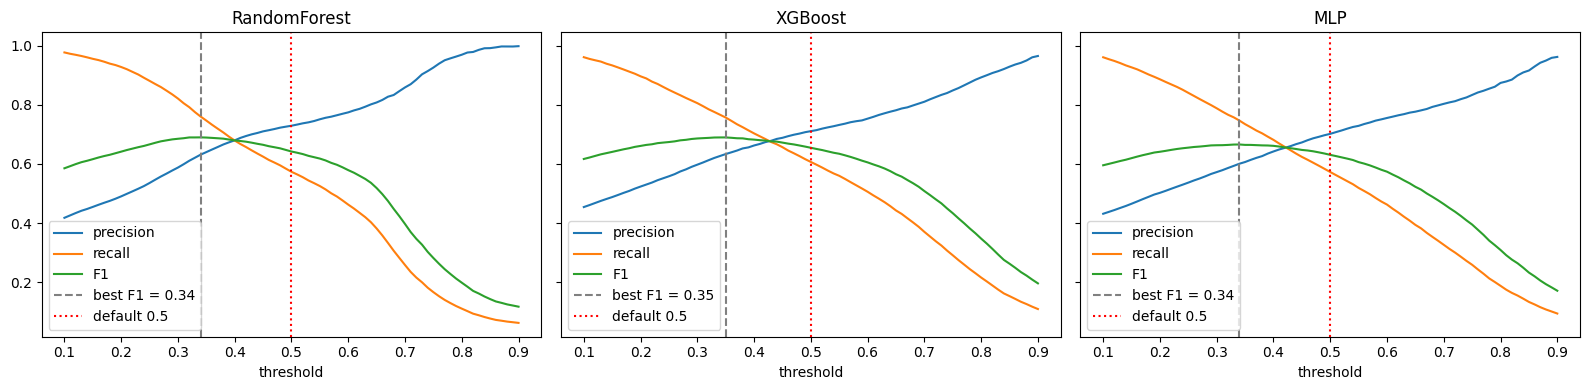

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, (name, sw) in zip(axes, sweeps.items()):
    ax.plot(sw["threshold"], sw["precision"], label="precision")
    ax.plot(sw["threshold"], sw["recall"],    label="recall")
    ax.plot(sw["threshold"], sw["f1"],        label="F1")
    best_t = sw.loc[sw["f1"].idxmax(), "threshold"]
    ax.axvline(best_t, color="gray", linestyle="--", label=f"best F1 = {best_t}")
    ax.axvline(0.5, color="red", linestyle=":", label="default 0.5")
    ax.set_title(name); ax.set_xlabel("threshold"); ax.legend()
plt.tight_layout()
plt.savefig("../../../outputs/classification_threshold_curves.png", dpi=150)
plt.show()

In [27]:
thr_table.to_csv("../../../outputs/classification_threshold_results.csv", index=False)

# The threshold we will actually use per model. Starts as best F1.
chosen_threshold = {name: float(sw.loc[sw["f1"].idxmax(), "threshold"])
                    for name, sw in sweeps.items()}
print(chosen_threshold)

with open("../../../outputs/classification_thresholds.json", "w") as f:
    json.dump(chosen_threshold, f, indent=2)

{'RandomForest': 0.34, 'XGBoost': 0.35, 'MLP': 0.34}


In [30]:
ratios = [1, 2, 3, 5]   # a miss costs this many times a false alarm
rows = []
for name, p in oof.items():
    for r in ratios:
        costs = []
        for t in thresholds:
            pred = (p >= t).astype(int)
            fn = ((pred == 0) & (y_train == 1)).sum()
            fp = ((pred == 1) & (y_train == 0)).sum()
            costs.append((r * fn + fp) / len(y_train))     # average cost per booking
        i = int(np.argmin(costs))
        rows.append({"model": name, "miss_costs_x": r,
                     "best_threshold": round(thresholds[i], 2),
                     "cost_per_booking": round(costs[i], 3)})
display(pd.DataFrame(rows))

,model,miss_costs_x,best_threshold,cost_per_booking
0,RandomForest,1,0.45,0.190
1,RandomForest,2,0.32,0.278
2,RandomForest,3,0.27,0.333
3,RandomForest,5,0.21,0.399
4,XGBoost,1,0.47,0.193
5,XGBoost,2,0.33,0.279
6,XGBoost,3,0.23,0.337
7,XGBoost,5,0.15,0.396
8,MLP,1,0.53,0.202
9,MLP,2,0.34,0.303


In [31]:
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix

thr_f1 = {n: float(sw.loc[sw["f1"].idxmax(), "threshold"]) for n, sw in sweeps.items()}
thr_hm = {n: float(sw.loc[sw["hm_2_1"].idxmax(), "threshold"]) for n, sw in sweeps.items()}

def test_row(label, name, proba, t):
    pred = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {"model": name, "version": label, "threshold": t,
            "accuracy": accuracy_score(y_test, pred),
            "precision": precision_score(y_test, pred, zero_division=0),
            "recall": recall_score(y_test, pred),
            "specificity": tn / (tn + fp),
            "f1": f1_score(y_test, pred),
            "hm_2_1": weighted_hm(y_test, pred, 2, 1),
            "roc_auc": roc_auc_score(y_test, proba),      # these two do not depend on the threshold
            "pr_auc": average_precision_score(y_test, proba),
            "TN": tn, "FP": fp, "FN": fn, "TP": tp}

test_rows = []
for name in ["RandomForest", "XGBoost", "MLP"]:
    model, scale, _ = to_tune[name]
    base = make_pipe(models[name][0], models[name][1]).fit(X_train, y_train)   # untuned baseline
    base_p = base.predict_proba(X_test)[:, 1]
    tuned_p = searches[name].best_estimator_.predict_proba(X_test)[:, 1]

    test_rows.append(test_row("baseline @0.50", name, base_p, 0.50))
    test_rows.append(test_row("tuned @0.50", name, tuned_p, 0.50))
    test_rows.append(test_row("tuned @best-F1", name, tuned_p, thr_f1[name]))
    test_rows.append(test_row("tuned @best-HM", name, tuned_p, thr_hm[name]))

test_table = pd.DataFrame(test_rows).round(4)
display(test_table)
test_table.to_csv("../../../outputs/classification_test_results.csv", index=False)

,model,version,threshold,accuracy,precision,recall,specificity,f1,hm_2_1,roc_auc,pr_auc,TN,FP,FN,TP
0,RandomForest,baseline @0.50,0.50,0.8333,0.7694,0.6955,0.8997,0.7306,0.7524,0.8975,0.8272,7497,836,1221,2789
1,RandomForest,tuned @0.50,0.50,0.8261,0.7883,0.6352,0.9179,0.7035,0.7078,0.8966,0.8231,7649,684,1463,2547
2,RandomForest,tuned @best-F1,0.34,0.8179,0.6884,0.8027,0.8252,0.7412,0.8101,0.8966,0.8231,6876,1457,791,3219
3,RandomForest,tuned @best-HM,0.27,0.7773,0.6082,0.8840,0.7259,0.7206,0.8242,0.8966,0.8231,6049,2284,465,3545
4,XGBoost,baseline @0.50,0.50,0.8201,0.7637,0.6464,0.9038,0.7002,0.7142,0.8899,0.8101,7531,802,1418,2592
5,XGBoost,tuned @0.50,0.50,0.8235,0.7675,0.6554,0.9045,0.7070,0.7216,0.8945,0.8189,7537,796,1382,2628
6,XGBoost,tuned @best-F1,0.35,0.8119,0.6818,0.7893,0.8228,0.7316,0.8001,0.8945,0.8189,6856,1477,845,3165
7,XGBoost,tuned @best-HM,0.23,0.7621,0.5878,0.8968,0.6973,0.7101,0.8187,0.8945,0.8189,5811,2522,414,3596
8,MLP,baseline @0.50,0.50,0.8075,0.7277,0.6511,0.8828,0.6873,0.7135,0.8765,0.7903,7356,977,1399,2611
9,MLP,tuned @0.50,0.50,0.8107,0.7705,0.5945,0.9148,0.6712,0.6731,0.8761,0.7917,7623,710,1626,2384


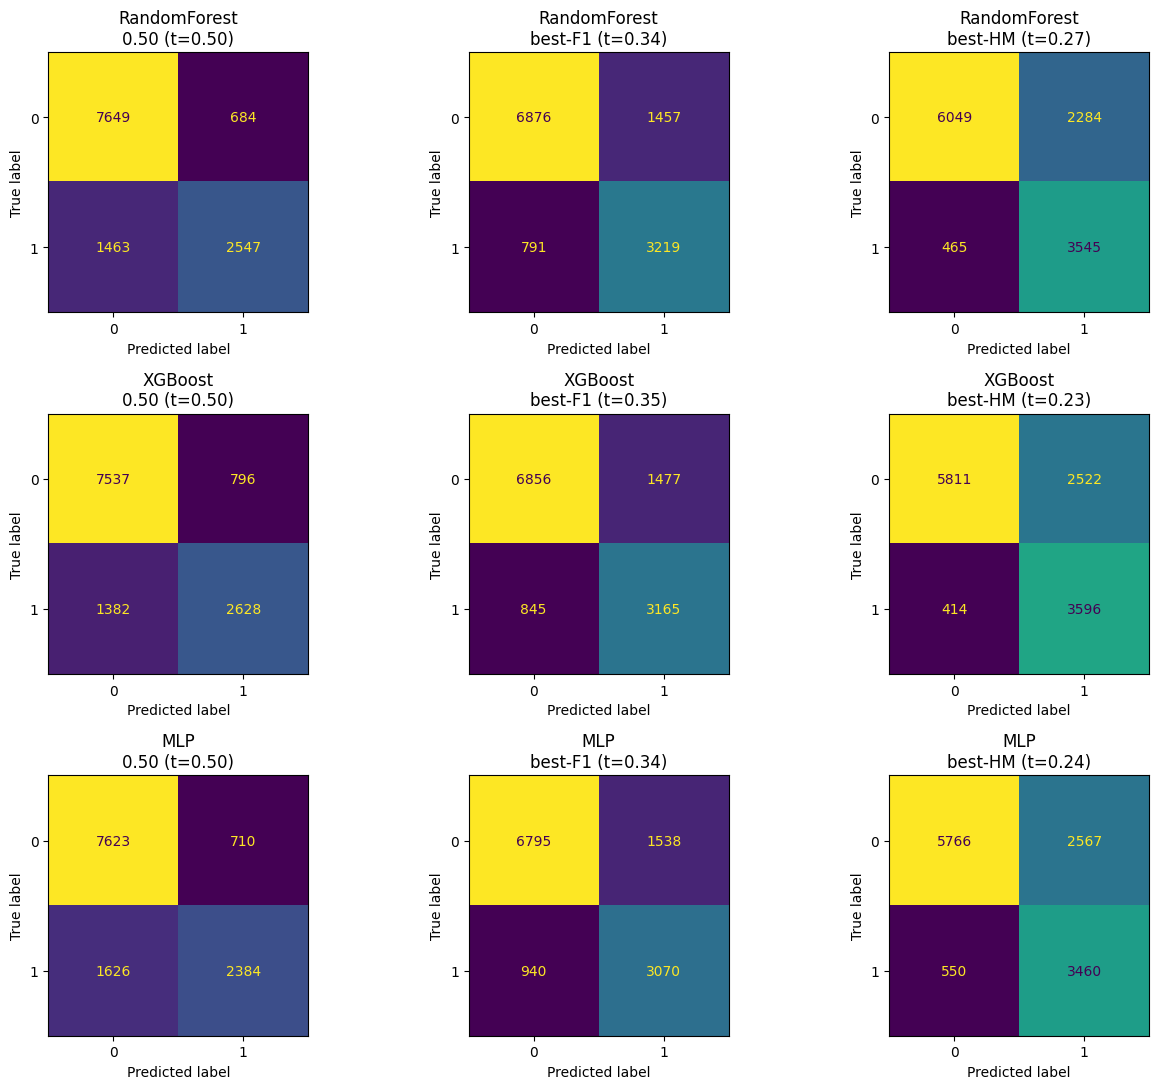

In [32]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(3, 3, figsize=(13, 11))
for i, name in enumerate(["RandomForest", "XGBoost", "MLP"]):
    p = searches[name].best_estimator_.predict_proba(X_test)[:, 1]
    for j, (lab, t) in enumerate([("0.50", 0.50), ("best-F1", thr_f1[name]), ("best-HM", thr_hm[name])]):
        ConfusionMatrixDisplay.from_predictions(
            y_test, (p >= t).astype(int), ax=axes[i, j], colorbar=False)
        axes[i, j].set_title(f"{name}\n{lab} (t={t:.2f})")
plt.tight_layout()
plt.savefig("../../../outputs/classification_test_confusion_matrices.png", dpi=150)
plt.show()

In [33]:
# The best model

# Random Forest (200 trees, depth 20, min leaf 1) with threshold 0.27.

# It was best on the CV (the decision we made before the test).
# It is also best on the test under both rules and on both AUCs. So the choice does not depend on which rule you use.
# MLP is clearly last on everything.
# XGBoost is very close, within about 0.005 on HM and 0.004 on PR-AUC.

In [ ]:
#-----------------------------END TUNING-----------------------------------------------------------------------------------

In [ ]:
#-----------------------------PCA & LDA-----------------------------------------------------------------------------------

In [34]:
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.base import clone

Features going into PCA: 53
80% of the variance needs 33 components
90% of the variance needs 39 components
95% of the variance needs 42 components
99% of the variance needs 46 components


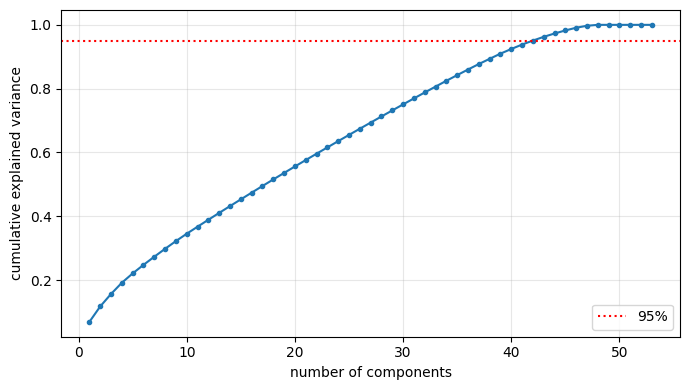

In [35]:
# Same encoder as make_pipe: Agent is target-encoded, everything else passes through
enc = ColumnTransformer(
    [("agent", TargetEncoder(target_type="binary", smooth="auto", cv=5, random_state=SEED), ["Agent"])],
    remainder="passthrough")

prep = Pipeline([("enc", enc), ("scaler", StandardScaler())])
Z = prep.fit_transform(X_train, y_train)     # y is only needed by the Agent target encoder
print("Features going into PCA:", Z.shape[1])

pca_full = PCA(random_state=SEED).fit(Z)     # keep ALL components, just to look
cum = np.cumsum(pca_full.explained_variance_ratio_)

for target in [0.80, 0.90, 0.95, 0.99]:
    k = int(np.argmax(cum >= target)) + 1
    print(f"{int(target*100)}% of the variance needs {k} components")

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(cum) + 1), cum, marker="o", markersize=3)
plt.axhline(0.95, color="red", linestyle=":", label="95%")
plt.xlabel("number of components"); plt.ylabel("cumulative explained variance")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig("../../../outputs/classification_pca_explained_variance.png", dpi=150)
plt.show()

In [36]:
def make_pipe_reduced(model, reducer):
    enc = ColumnTransformer(
        [("agent", TargetEncoder(target_type="binary", smooth="auto", cv=5, random_state=SEED), ["Agent"])],
        remainder="passthrough")
    return Pipeline([("enc", enc),
                     ("scaler", StandardScaler()),
                     ("reduce", reducer),        # PCA or LDA
                     ("model", model)])

def run_cv_pipe(model_name, rep, pipe):
    """5-fold CV of a ready pipeline. Same metrics as before."""
    start = time.time()
    res = cross_validate(pipe, X_train, y_train, cv=cv5, scoring=scoring, n_jobs=-1)
    row = {"model": model_name, "features": rep}
    for m in scoring:
        row[f"cv_{m}"] = res[f"test_{m}"].mean()
    row["cv_f1_std"] = res["test_f1"].std()
    row["time_sec"] = time.time() - start
    return row

PCA k = 5
PCA k = 10
PCA k = 15
PCA k = 20
PCA k = 25
PCA k = 30
PCA k = 40


,k,cv_pr_auc,cv_f1,cv_recall,time_sec
0,5,0.6238,0.5178,0.4444,6.7452
1,10,0.6822,0.5861,0.5243,4.5365
2,15,0.6902,0.5965,0.5361,6.6985
3,20,0.6908,0.5974,0.5386,7.2569
4,25,0.6920,0.6017,0.5447,10.4625
5,30,0.6950,0.6040,0.5475,11.4819
6,40,0.7031,0.6141,0.5596,15.3485


Original (no PCA): PR-AUC 0.7488  F1 0.6548


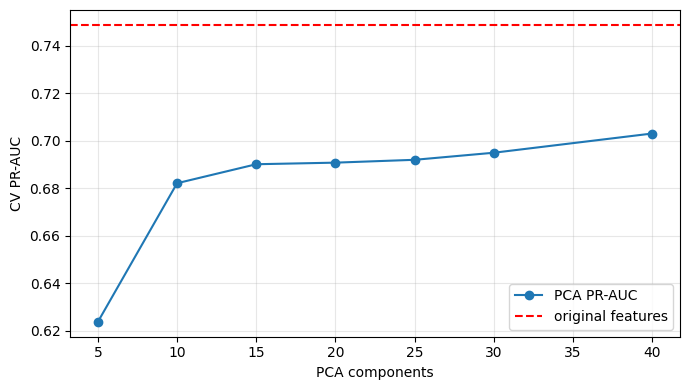

In [37]:
best_xgb = clone(searches["XGBoost"].best_estimator_.named_steps["model"])   # tuned settings

ref = run_cv_pipe("XGBoost", "original", make_pipe(clone(best_xgb), scale=False))

sweep_rows = []
for k in [5, 10, 15, 20, 25, 30, 40]:
    print("PCA k =", k, flush=True)
    r = run_cv_pipe("XGBoost", f"PCA_{k}", make_pipe_reduced(clone(best_xgb), PCA(n_components=k, random_state=SEED)))
    r["k"] = k
    sweep_rows.append(r)

pca_sweep = pd.DataFrame(sweep_rows)
display(pca_sweep[["k", "cv_pr_auc", "cv_f1", "cv_recall", "time_sec"]].round(4))
print("Original (no PCA): PR-AUC", round(ref["cv_pr_auc"], 4), " F1", round(ref["cv_f1"], 4))

plt.figure(figsize=(7, 4))
plt.plot(pca_sweep["k"], pca_sweep["cv_pr_auc"], marker="o", label="PCA PR-AUC")
plt.axhline(ref["cv_pr_auc"], color="red", linestyle="--", label="original features")
plt.xlabel("PCA components"); plt.ylabel("CV PR-AUC"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../../../outputs/classification_pca_components_sweep.png", dpi=150)
plt.show()
pca_sweep.to_csv("../../../outputs/classification_pca_sweep.csv", index=False)

PCA k = 42
PCA k = 46
PCA k = 50
PCA k = 53


,k,cv_pr_auc,cv_f1,cv_recall,time_sec
0,5,0.6238,0.5178,0.4444,6.7452
1,10,0.6822,0.5861,0.5243,4.5365
2,15,0.6902,0.5965,0.5361,6.6985
3,20,0.6908,0.5974,0.5386,7.2569
4,25,0.6920,0.6017,0.5447,10.4625
5,30,0.6950,0.6040,0.5475,11.4819
6,40,0.7031,0.6141,0.5596,15.3485
7,42,0.7046,0.6183,0.5659,9.6872
8,46,0.7162,0.6281,0.5793,10.9983
9,50,0.7224,0.6345,0.5862,11.1921


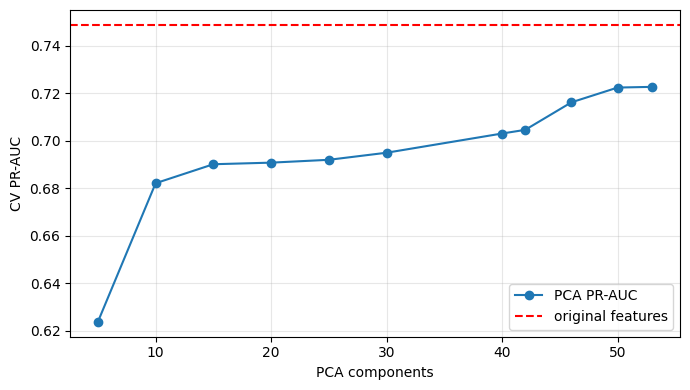

In [38]:
more_rows = []
for k in [42, 46, 50, 53]:
    print("PCA k =", k, flush=True)
    r = run_cv_pipe("XGBoost", f"PCA_{k}", make_pipe_reduced(clone(best_xgb), PCA(n_components=k, random_state=SEED)))
    r["k"] = k
    more_rows.append(r)

pca_sweep = pd.concat([pca_sweep, pd.DataFrame(more_rows)], ignore_index=True)
display(pca_sweep[["k", "cv_pr_auc", "cv_f1", "cv_recall", "time_sec"]].round(4))

plt.figure(figsize=(7, 4))
plt.plot(pca_sweep["k"], pca_sweep["cv_pr_auc"], marker="o", label="PCA PR-AUC")
plt.axhline(ref["cv_pr_auc"], color="red", linestyle="--", label="original features")
plt.xlabel("PCA components"); plt.ylabel("CV PR-AUC"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../../../outputs/classification_pca_components_sweep.png", dpi=150)
plt.show()
pca_sweep.to_csv("../../../outputs/classification_pca_sweep.csv", index=False)

In [40]:
N_PCA = 50

In [41]:
rows = []
for name in ["RandomForest", "XGBoost", "MLP"]:
    tuned = searches[name].best_estimator_.named_steps["model"]   # tuned settings from Segment 6
    scale = to_tune[name][1]
    print("running", name, flush=True)

    rows.append(run_cv_pipe(name, "original", make_pipe(clone(tuned), scale)))
    rows.append(run_cv_pipe(name, f"PCA_{N_PCA}",
                            make_pipe_reduced(clone(tuned), PCA(n_components=N_PCA, random_state=SEED))))
    rows.append(run_cv_pipe(name, "LDA_1",
                            make_pipe_reduced(clone(tuned), LinearDiscriminantAnalysis(n_components=1))))

# Extra: LDA used directly as a classifier
rows.append(run_cv_pipe("LDA_classifier", "original", make_pipe(LinearDiscriminantAnalysis(), scale=True)))

dimred = pd.DataFrame(rows).round(4)
display(dimred)
dimred.to_csv("../../../outputs/classification_pca_lda_comparison_cv.csv", index=False)

display(dimred.pivot(index="model", columns="features", values="cv_pr_auc"))
display(dimred.pivot(index="model", columns="features", values="cv_f1"))

running RandomForest
running XGBoost
running MLP


,model,features,cv_accuracy,cv_precision,cv_recall,cv_f1,cv_roc_auc,cv_pr_auc,cv_hm_1_1,cv_hm_2_1,cv_hm_3_1,cv_f1_std,time_sec
0,RandomForest,original,0.8068,0.7297,0.5735,0.6422,0.8703,0.7499,0.7030,0.6538,0.6317,0.0025,17.2306
1,RandomForest,PCA_50,0.7890,0.6860,0.5566,0.6145,0.8388,0.7003,0.6847,0.6359,0.6140,0.0077,94.6855
2,RandomForest,LDA_1,0.7497,0.6082,0.4834,0.5386,0.7798,0.6201,0.6201,0.5667,0.5433,0.0080,15.8382
3,XGBoost,original,0.8067,0.7114,0.6068,0.6548,0.8707,0.7488,0.7226,0.6794,0.6597,0.0045,3.3344
4,XGBoost,PCA_50,0.7959,0.6915,0.5862,0.6345,0.8535,0.7224,0.7058,0.6608,0.6404,0.0052,13.0770
5,XGBoost,LDA_1,0.7693,0.6505,0.5118,0.5728,0.8059,0.6548,0.6473,0.5948,0.5716,0.0070,1.8107
6,MLP,original,0.7974,0.7024,0.5728,0.6306,0.8544,0.7236,0.6980,0.6506,0.6292,0.0108,9.9835
7,MLP,PCA_50,0.7946,0.6897,0.5842,0.6321,0.8533,0.7233,0.7036,0.6587,0.6383,0.0108,8.2479
8,MLP,LDA_1,0.7699,0.6504,0.5195,0.5761,0.8089,0.6594,0.6512,0.6002,0.5777,0.0231,4.9683
9,LDA_classifier,original,0.7676,0.6778,0.4411,0.5342,0.8089,0.6594,0.5938,0.5323,0.5062,0.0074,0.8078


features,LDA_1,PCA_50,original
model,,,
LDA_classifier,NaN,NaN,0.6594
MLP,0.6594,0.7233,0.7236
RandomForest,0.6201,0.7003,0.7499
XGBoost,0.6548,0.7224,0.7488


features,LDA_1,PCA_50,original
model,,,
LDA_classifier,NaN,NaN,0.5342
MLP,0.5761,0.6321,0.6306
RandomForest,0.5386,0.6145,0.6422
XGBoost,0.5728,0.6345,0.6548


In [42]:
test_rows = []
for name in ["RandomForest", "XGBoost", "MLP"]:
    tuned = searches[name].best_estimator_.named_steps["model"]
    scale = to_tune[name][1]
    variants = {
        "original": make_pipe(clone(tuned), scale),
        f"PCA_{N_PCA}": make_pipe_reduced(clone(tuned), PCA(n_components=N_PCA, random_state=SEED)),
        "LDA_1": make_pipe_reduced(clone(tuned), LinearDiscriminantAnalysis(n_components=1)),
    }
    for rep, pipe in variants.items():
        pipe.fit(X_train, y_train)
        p = pipe.predict_proba(X_test)[:, 1]
        pred = (p >= 0.5).astype(int)
        test_rows.append({"model": name, "features": rep,
                          "accuracy": accuracy_score(y_test, pred),
                          "precision": precision_score(y_test, pred, zero_division=0),
                          "recall": recall_score(y_test, pred),
                          "f1": f1_score(y_test, pred),
                          "roc_auc": roc_auc_score(y_test, p),
                          "pr_auc": average_precision_score(y_test, p)})

dimred_test = pd.DataFrame(test_rows).round(4)
display(dimred_test)
dimred_test.to_csv("../../../outputs/classification_pca_lda_test_results.csv", index=False)

,model,features,accuracy,precision,recall,f1,roc_auc,pr_auc
0,RandomForest,original,0.8261,0.7883,0.6352,0.7035,0.8966,0.8231
1,RandomForest,PCA_50,0.8265,0.7725,0.6606,0.7122,0.8865,0.8168
2,RandomForest,LDA_1,0.7561,0.6608,0.5120,0.5769,0.7981,0.6857
3,XGBoost,original,0.8235,0.7675,0.6554,0.7070,0.8945,0.8189
4,XGBoost,PCA_50,0.8248,0.7651,0.6646,0.7113,0.8923,0.8169
5,XGBoost,LDA_1,0.7771,0.6984,0.5526,0.6170,0.8220,0.7218
6,MLP,original,0.8107,0.7705,0.5945,0.6712,0.8761,0.7917
7,MLP,PCA_50,0.8105,0.7399,0.6426,0.6878,0.8782,0.7912
8,MLP,LDA_1,0.7778,0.7080,0.5377,0.6112,0.8237,0.7240


In [ ]:
#-----------------------------  EXTRA MODELS OUTSIDE DESCRIPTION -----------------------------------------------------------------------------------

In [43]:
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, VotingClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

extra_models = {
    "ExtraTrees": ExtraTreesClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    "HistGB":     HistGradientBoostingClassifier(random_state=SEED),
    "LightGBM":   LGBMClassifier(random_state=SEED, verbose=-1),
    "CatBoost":   CatBoostClassifier(random_seed=SEED, verbose=0),
}

extra_rows = []
for name, m in extra_models.items():
    print("running", name, flush=True)
    extra_rows.append(run_cv_pipe(name, "original", make_pipe(m, scale=False)))

# Soft voting: average the probabilities of the 3 tuned models
tuned = {n: clone(searches[n].best_estimator_.named_steps["model"]) for n in ["RandomForest", "XGBoost", "MLP"]}
voter = VotingClassifier(
    estimators=[("rf", tuned["RandomForest"]), ("xgb", tuned["XGBoost"]), ("mlp", tuned["MLP"])],
    voting="soft", n_jobs=1)
extra_rows.append(run_cv_pipe("Voting_RF_XGB_MLP", "original", make_pipe(voter, scale=True)))

extra = pd.DataFrame(extra_rows).round(4)
display(extra[["model", "cv_pr_auc", "cv_roc_auc", "cv_f1", "cv_recall", "cv_hm_2_1", "time_sec"]])
extra.to_csv("../../../outputs/classification_extra_models_cv.csv", index=False)

running ExtraTrees
running HistGB
running LightGBM
running CatBoost


,model,cv_pr_auc,cv_roc_auc,cv_f1,cv_recall,cv_hm_2_1,time_sec
0,ExtraTrees,0.7024,0.8449,0.6287,0.5883,0.6608,33.9035
1,HistGB,0.7420,0.8671,0.6475,0.5928,0.6682,9.6065
2,LightGBM,0.7434,0.8679,0.6475,0.5922,0.6679,5.0469
3,CatBoost,0.7521,0.8726,0.6562,0.6054,0.6787,28.4372
4,Voting_RF_XGB_MLP,0.7526,0.8725,0.6494,0.5874,0.6649,27.3594


In [44]:
from catboost import CatBoostClassifier

spaces["CatBoost"] = {
    "model__iterations":    [300, 500, 800],        # number of trees
    "model__depth":         [4, 6, 8],              # how deep each tree is
    "model__learning_rate": [0.03, 0.05, 0.1, 0.2], # step size
    "model__l2_leaf_reg":   [1, 3, 5, 10],          # regularization (higher = simpler model)
}

# thread_count=1 stops CatBoost from fighting with n_jobs=-1 for CPU cores
to_tune["CatBoost"] = (CatBoostClassifier(random_seed=SEED, verbose=0, thread_count=1), False, 15)

tune("CatBoost")

Fitting 5 folds for each of 15 candidates, totalling 75 fits
CatBoost | best PR-AUC: 0.7542 | time: 185.2 sec
best settings: {'model__learning_rate': 0.05, 'model__l2_leaf_reg': 3, 'model__iterations': 800, 'model__depth': 8}


In [45]:
r = pd.DataFrame(searches["CatBoost"].cv_results_)
cols = [c for c in r.columns if c.startswith("param_")] + ["mean_test_pr_auc", "mean_test_f1", "mean_test_recall", "mean_fit_time"]
display(r[cols].sort_values("mean_test_pr_auc", ascending=False).head(5).round(4))

,param_model__learning_rate,param_model__l2_leaf_reg,param_model__iterations,param_model__depth,mean_test_pr_auc,mean_test_f1,mean_test_recall,mean_fit_time
13,0.05,3,800,8,0.7542,0.6598,0.6114,35.1617
6,0.03,3,800,8,0.7536,0.6561,0.6040,37.0448
0,0.05,3,500,8,0.7529,0.6581,0.6069,18.8702
2,0.10,1,800,6,0.7521,0.6588,0.6138,20.1084
12,0.10,10,800,6,0.7519,0.6574,0.6085,20.3951


In [46]:
# out-of-fold probabilities + threshold sweep (same code style as before)
p_cat = cross_val_predict(searches["CatBoost"].best_estimator_, X_train, y_train,
                          cv=cv5, method="predict_proba", n_jobs=-1)[:, 1]
sw_cat = sweep(y_train, p_cat)
t_f1  = float(sw_cat.loc[sw_cat["f1"].idxmax(), "threshold"])
t_hm  = float(sw_cat.loc[sw_cat["hm_2_1"].idxmax(), "threshold"])
print("best-F1 threshold:", t_f1, "| best-HM threshold:", t_hm)

# one test evaluation, using your test_row helper
cat_test = searches["CatBoost"].best_estimator_.predict_proba(X_test)[:, 1]
cat_rows = [test_row("tuned @0.50", "CatBoost", cat_test, 0.50),
            test_row("tuned @best-F1", "CatBoost", cat_test, t_f1),
            test_row("tuned @best-HM", "CatBoost", cat_test, t_hm)]
display(pd.DataFrame(cat_rows).round(4))
pd.DataFrame(cat_rows).round(4).to_csv("../../../outputs/classification_test_results_catboost.csv", index=False)

best-F1 threshold: 0.32 | best-HM threshold: 0.25


,model,version,threshold,accuracy,precision,recall,specificity,f1,hm_2_1,roc_auc,pr_auc,TN,FP,FN,TP
0,CatBoost,tuned @0.50,0.50,0.8245,0.7713,0.6536,0.9068,0.7076,0.7207,0.8946,0.817,7556,777,1389,2621
1,CatBoost,tuned @best-F1,0.32,0.8049,0.6618,0.8170,0.7991,0.7312,0.8109,0.8946,0.817,6659,1674,734,3276
2,CatBoost,tuned @best-HM,0.25,0.7746,0.6061,0.8748,0.7264,0.7161,0.8190,0.8946,0.817,6053,2280,502,3508


In [47]:
pd.DataFrame(searches["CatBoost"].cv_results_).to_csv("../../../outputs/classification_tuning_CatBoost.csv", index=False)
joblib.dump(searches["CatBoost"].best_estimator_, "../../../artifacts/CatBoost_tuned_cv5.joblib")

['../../../artifacts/CatBoost_tuned_cv5.joblib']